In [ ]:
#Correlation Power Analysis


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [18]:
#loading traces and hypothesis
data = np.load(
    "results/preprocessing/preprocessed_data.npz"
)

traces = data["traces"]

print(traces.shape)

hypothesis_data = np.load(
    "results/leakage_model/hd_hypotheses.npz"
)

H0 = hypothesis_data["byte_0"]

print(H0.shape)

(100000, 200)
(100000, 256)


In [19]:
#correlation function
def correlation_matrix(H, T):

    H = H.astype(np.float64)
    T = T.astype(np.float64)

    H_centered = H - H.mean(
        axis=0,
        keepdims=True
    )

    T_centered = T - T.mean(
        axis=0,
        keepdims=True
    )

    numerator = H_centered.T @ T_centered

    H_norm = np.sqrt(
        np.sum(H_centered ** 2, axis=0)
    )

    T_norm = np.sqrt(
        np.sum(T_centered ** 2, axis=0)
    )

    denominator = (
        H_norm[:, None]
        * T_norm[None, :]
    )

    return numerator / denominator

(256, 200)
Best key: 0x91
Peak sample: 49
Correlation: -0.13203417570655135
Absolute correlation: 0.13203417570655135


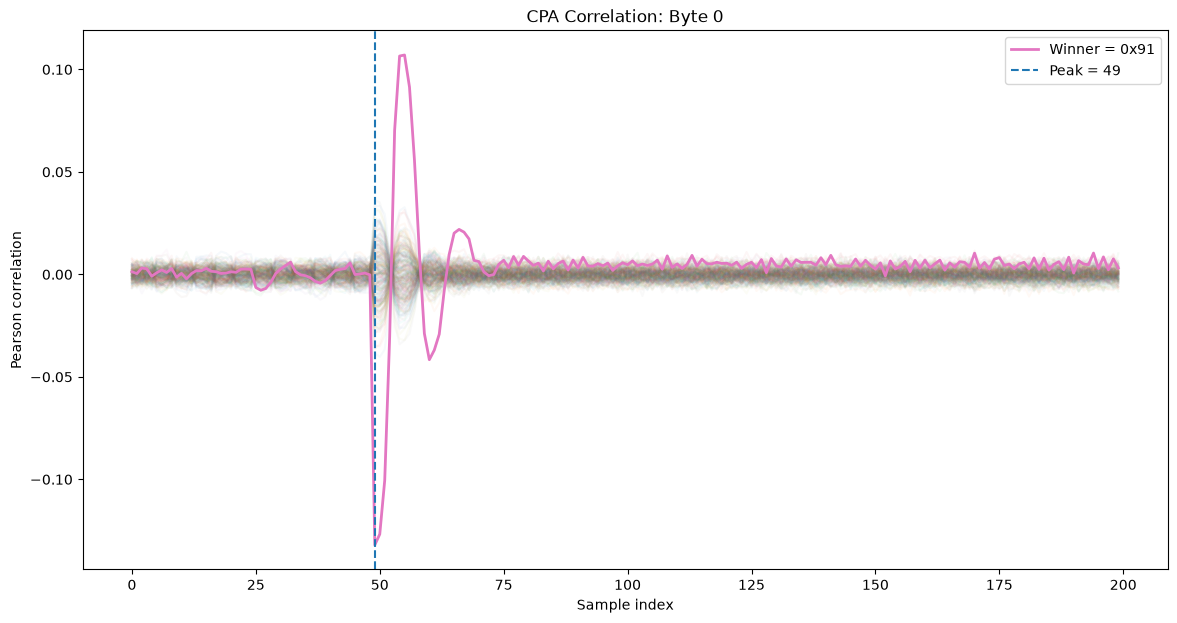

In [20]:
R0 = correlation_matrix(
    H0,
    traces
)
print(R0.shape)

scores0 = np.max(
    np.abs(R0),
    axis=1
)

best_key0 = int(
    np.argmax(scores0)
)

peak_sample0 = int(
    np.argmax(
        np.abs(R0[best_key0])
    )
)

peak_corr0 = R0[
    best_key0,
    peak_sample0
]

print(f"Best key: 0x{best_key0:02X}")
print("Peak sample:", peak_sample0)
print("Correlation:", peak_corr0)
print("Absolute correlation:", abs(peak_corr0))

plt.figure(figsize=(14, 7))

for k in range(256):
    plt.plot(
        R0[k],
        alpha=0.04
    )

plt.plot(
    R0[best_key0],
    linewidth=2,
    label=f"Winner = 0x{best_key0:02X}"
)

plt.axvline(
    peak_sample0,
    linestyle="--",
    label=f"Peak = {peak_sample0}"
)

plt.xlabel("Sample index")
plt.ylabel("Pearson correlation")
plt.title("CPA Correlation: Byte 0")
plt.legend()

plt.show()

In [21]:
#top 10 candidates
ranking = np.argsort(
    scores0
)[::-1]

for rank, key in enumerate(
    ranking[:10],
    start=1
):

    print(
        f"Rank {rank}: "
        f"0x{key:02X} "
        f"| |r| = {scores0[key]:.6f}"
    )

Rank 1: 0x91 | |r| = 0.132034
Rank 2: 0x46 | |r| = 0.040293
Rank 3: 0xA1 | |r| = 0.036380
Rank 4: 0x4D | |r| = 0.036243
Rank 5: 0xB7 | |r| = 0.035127
Rank 6: 0x14 | |r| = 0.033446
Rank 7: 0x6C | |r| = 0.032151
Rank 8: 0x58 | |r| = 0.031830
Rank 9: 0xD5 | |r| = 0.029934
Rank 10: 0x03 | |r| = 0.028799


In [22]:
#CPA on 16 bytes
results = []
correlation_matrices = {}

for byte_index in range(16):

    print(f"Attacking byte {byte_index}...")

    H = hypothesis_data[
        f"byte_{byte_index}"
    ]

    R = correlation_matrix(
        H,
        traces
    )

    correlation_matrices[
        byte_index
    ] = R

    scores = np.max(
        np.abs(R),
        axis=1
    )

    best_key = int(
        np.argmax(scores)
    )

    peak_sample = int(
        np.argmax(
            np.abs(R[best_key])
        )
    )

    peak_corr = float(
        R[best_key, peak_sample]
    )

    results.append({
        "byte": byte_index,
        "key": best_key,
        "peak_sample": peak_sample,
        "correlation": peak_corr,
        "abs_correlation": abs(peak_corr)
    })

    print(
        f"  Key = 0x{best_key:02X}, "
        f"sample = {peak_sample}, "
        f"|r| = {abs(peak_corr):.6f}"
    )

Attacking byte 0...
  Key = 0x91, sample = 49, |r| = 0.132034
Attacking byte 1...
  Key = 0xDE, sample = 49, |r| = 0.135437
Attacking byte 2...
  Key = 0xC0, sample = 49, |r| = 0.144975
Attacking byte 3...
  Key = 0x68, sample = 49, |r| = 0.131470
Attacking byte 4...
  Key = 0xE3, sample = 49, |r| = 0.119641
Attacking byte 5...
  Key = 0xFA, sample = 50, |r| = 0.129257
Attacking byte 6...
  Key = 0xCE, sample = 49, |r| = 0.126033
Attacking byte 7...
  Key = 0x45, sample = 49, |r| = 0.128424
Attacking byte 8...
  Key = 0x99, sample = 49, |r| = 0.124603
Attacking byte 9...
  Key = 0xCE, sample = 49, |r| = 0.138324
Attacking byte 10...
  Key = 0x38, sample = 49, |r| = 0.131500
Attacking byte 11...
  Key = 0xF4, sample = 49, |r| = 0.140764
Attacking byte 12...
  Key = 0x20, sample = 49, |r| = 0.132874
Attacking byte 13...
  Key = 0x86, sample = 49, |r| = 0.122103
Attacking byte 14...
  Key = 0x3A, sample = 49, |r| = 0.118693
Attacking byte 15...
  Key = 0x30, sample = 50, |r| = 0.178075


In [23]:
#fake key construction
results_df = pd.DataFrame(results)

fake_key = bytes(
    results_df["key"].tolist()
)

print("Recovered fake round-10 key:")
print(
    " ".join(
        f"{b:02X}"
        for b in fake_key
    )
)

Recovered fake round-10 key:
91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30


In [24]:
#saving result
Path("results/cpa").mkdir(
    parents=True,
    exist_ok=True
)

results_df.to_csv(
    "results/cpa/fake_key_results.csv",
    index=False
)

with open(
    "results/cpa/fake_round10_key.txt",
    "w"
) as f:

    f.write(
        fake_key.hex()
    )

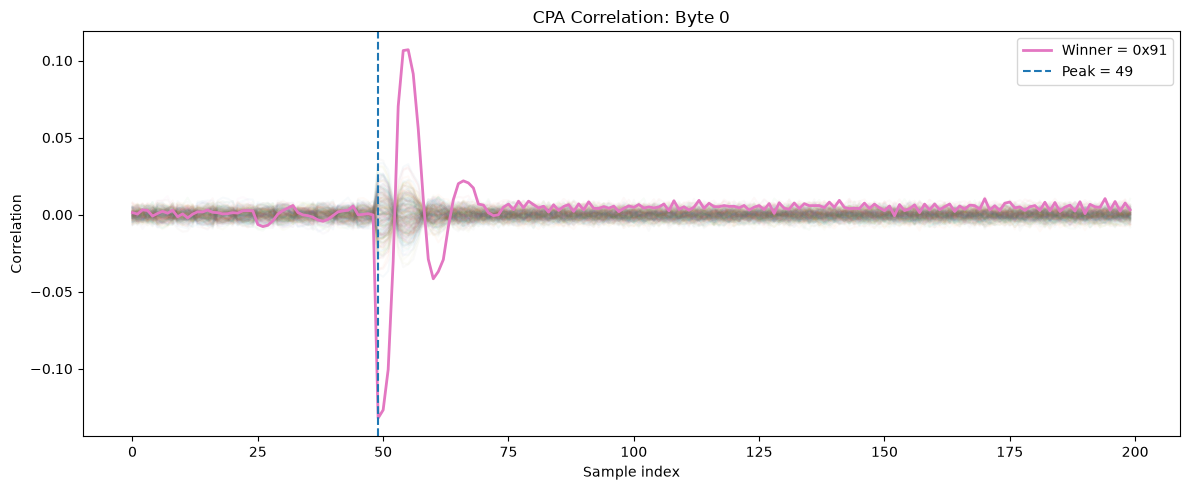

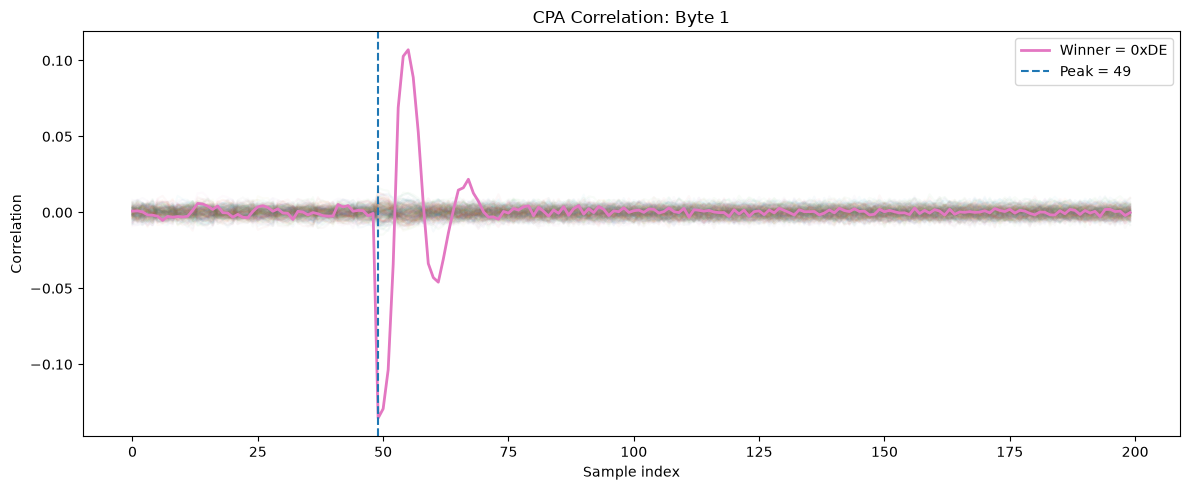

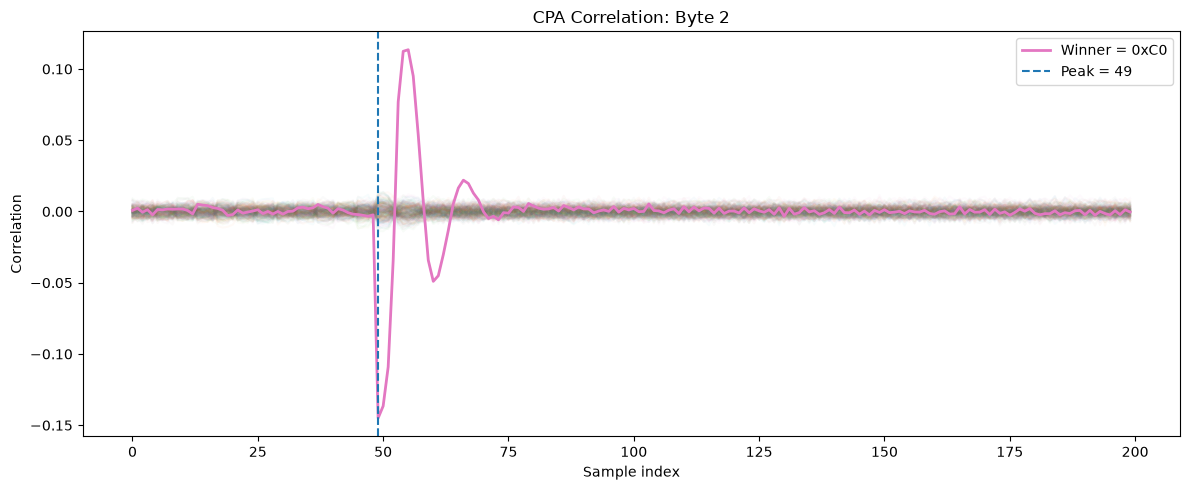

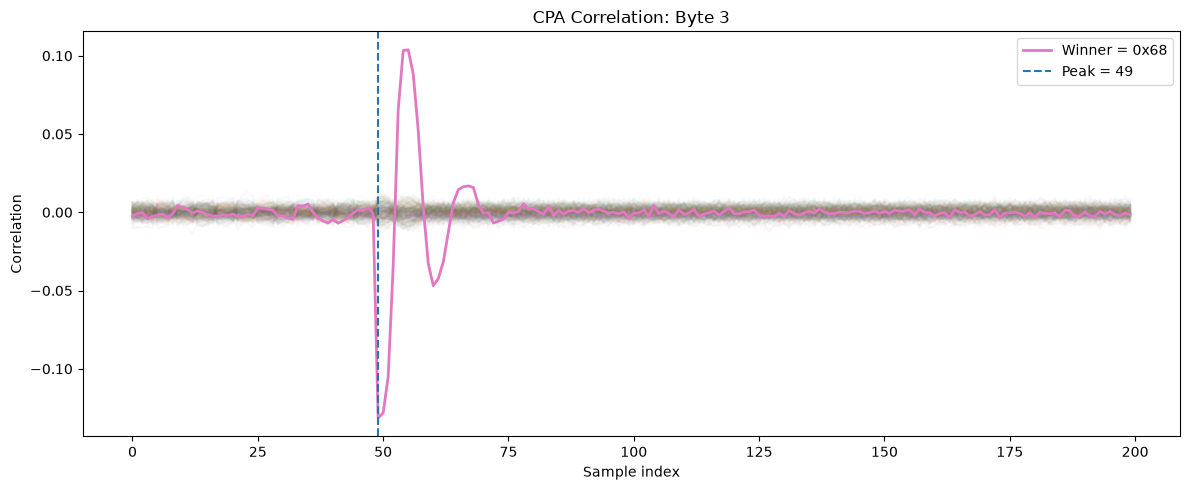

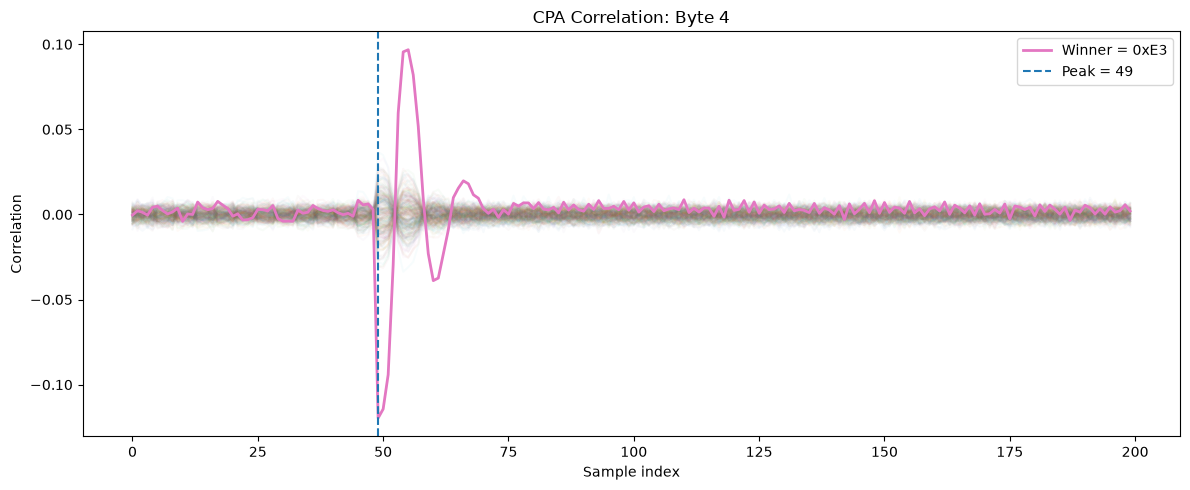

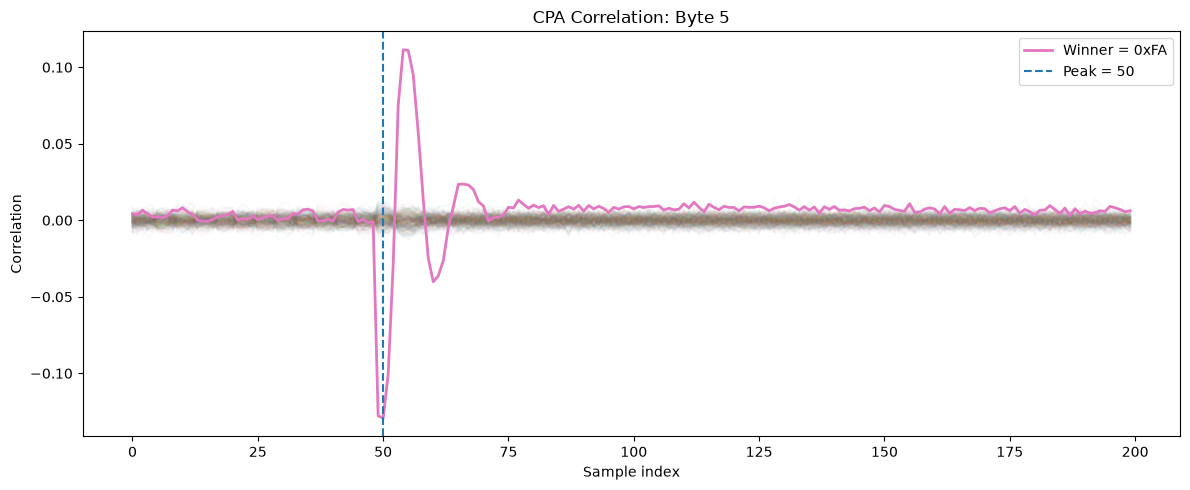

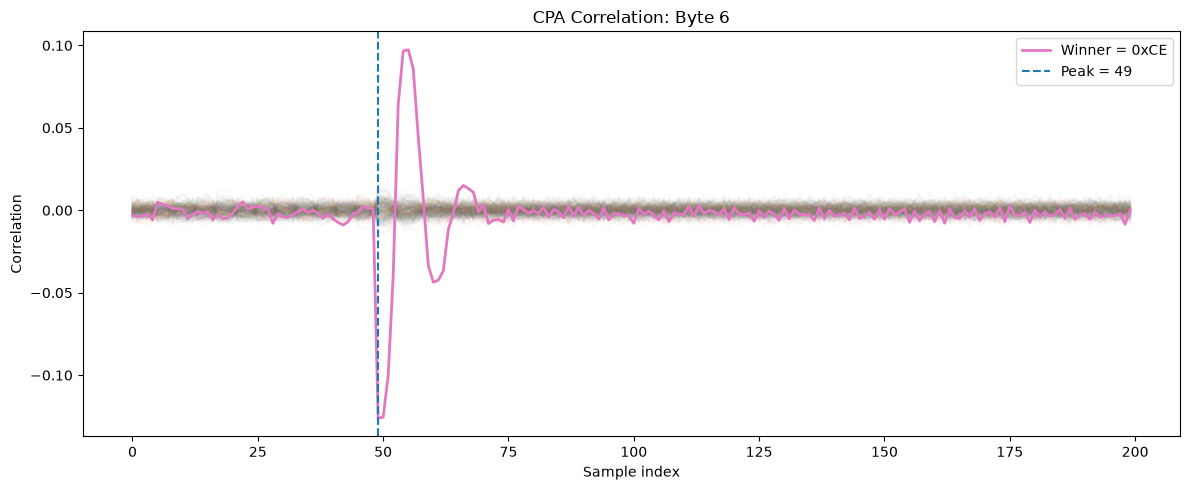

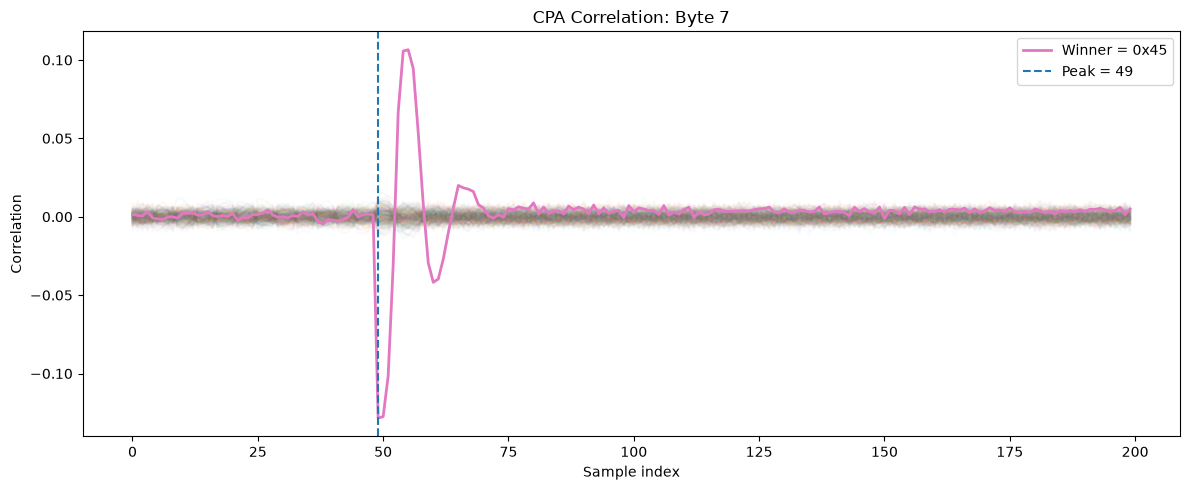

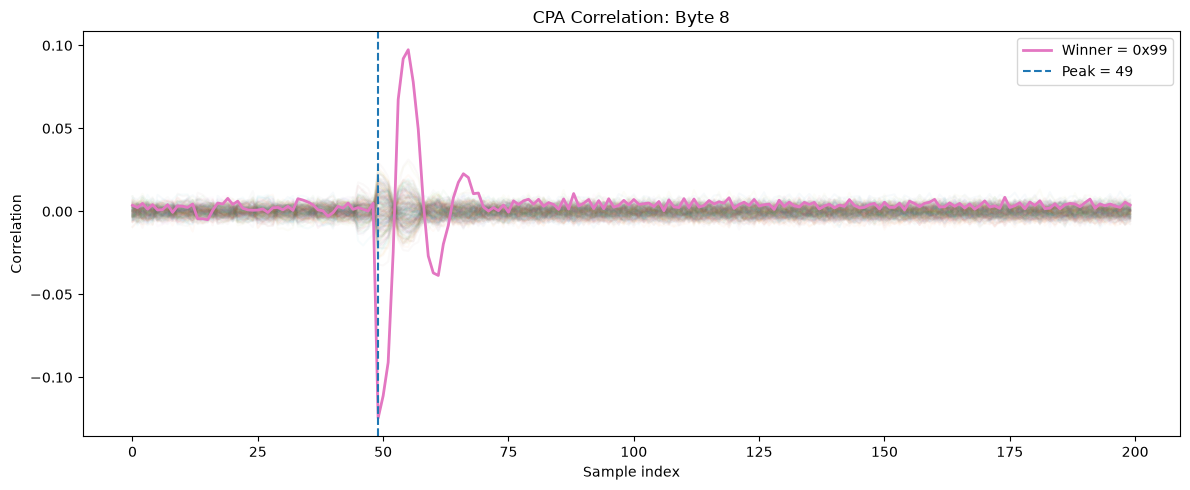

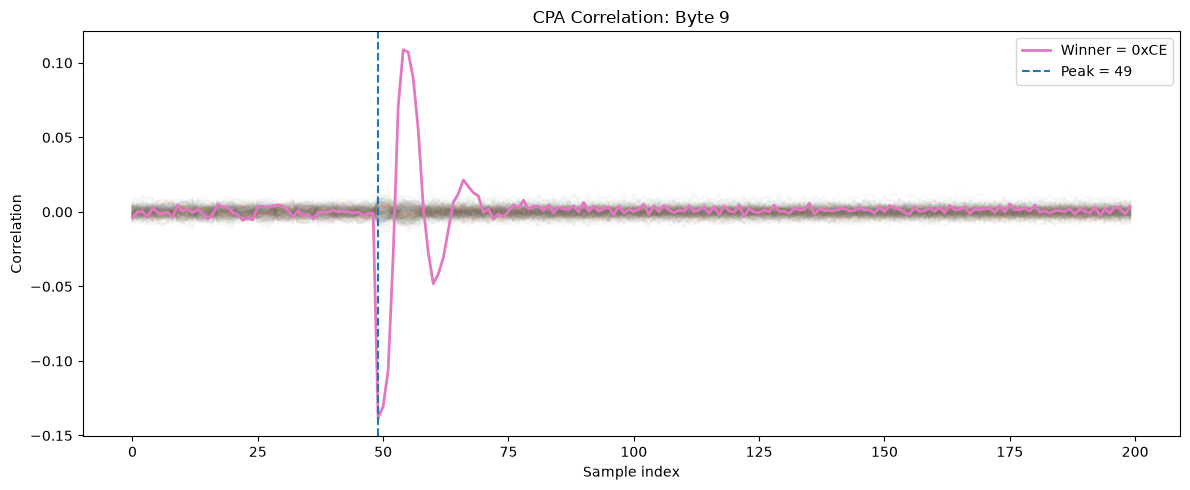

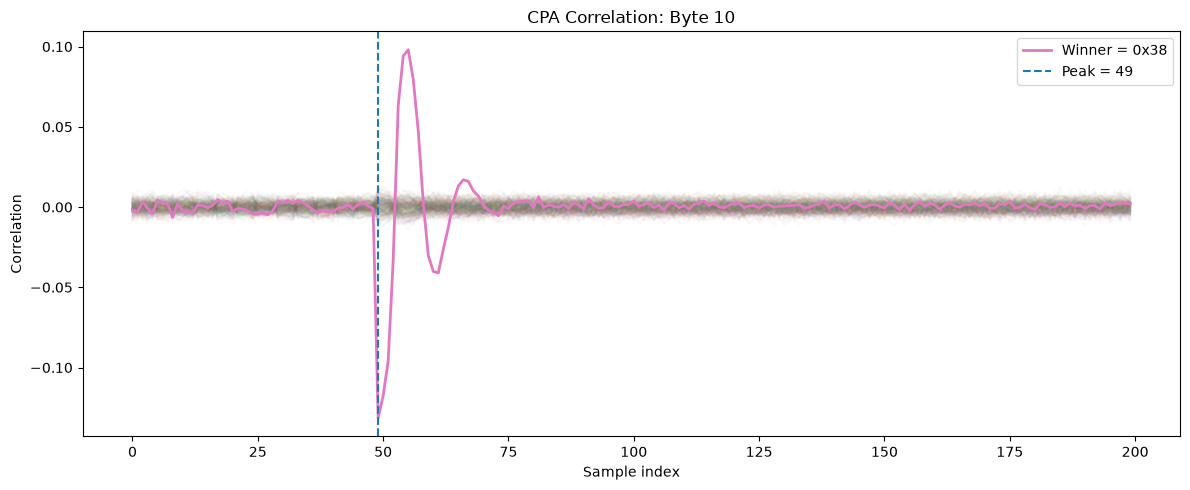

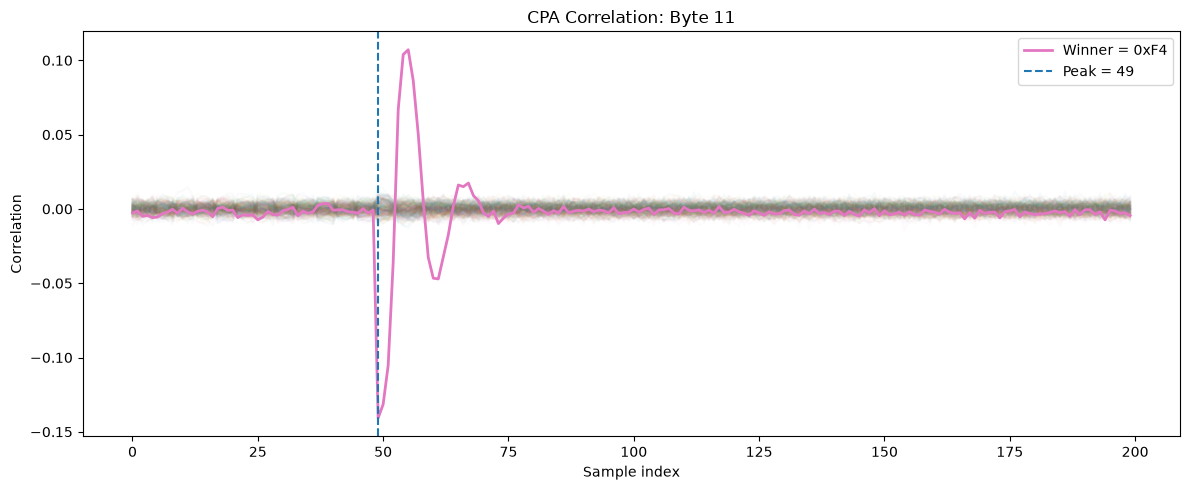

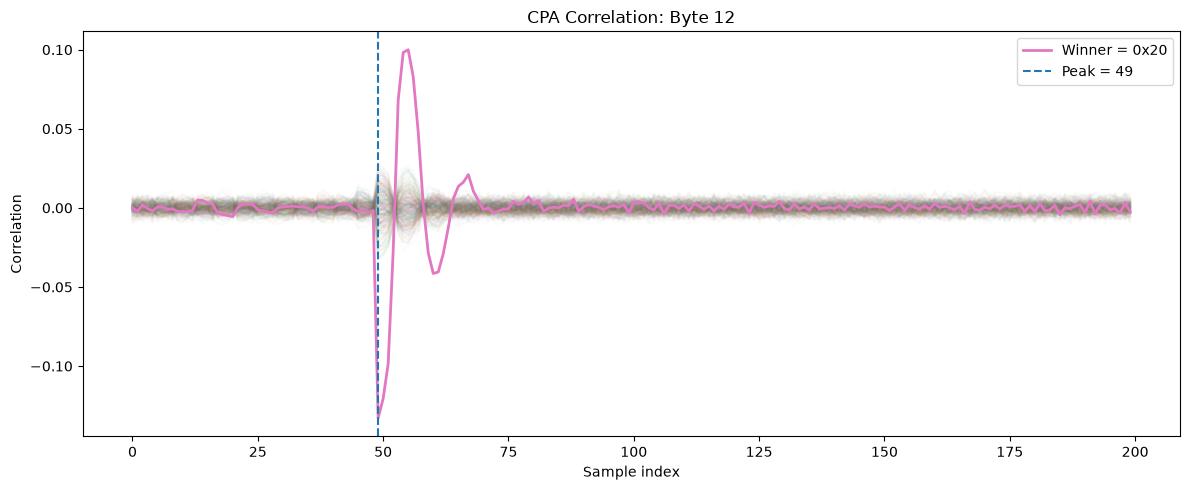

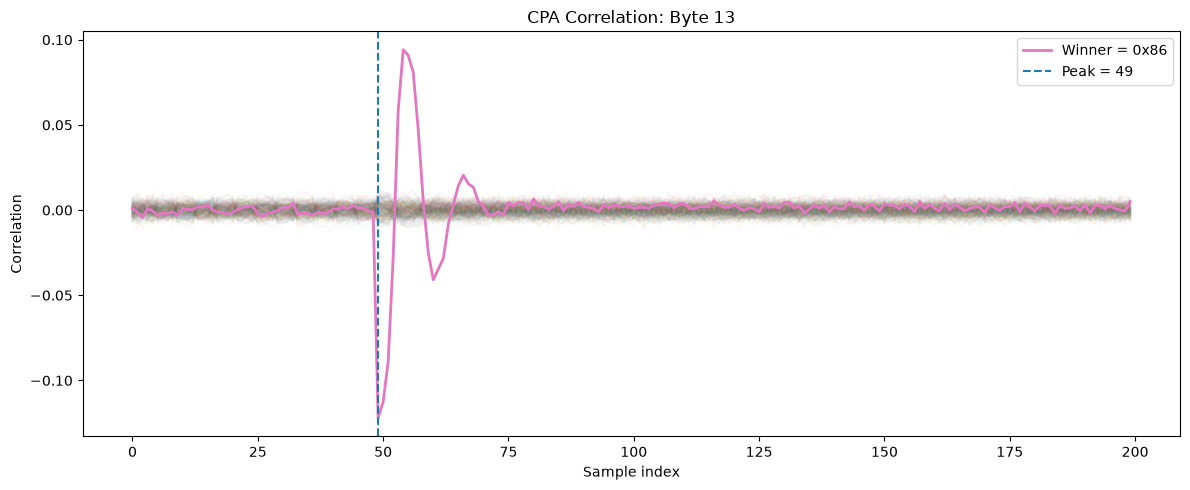

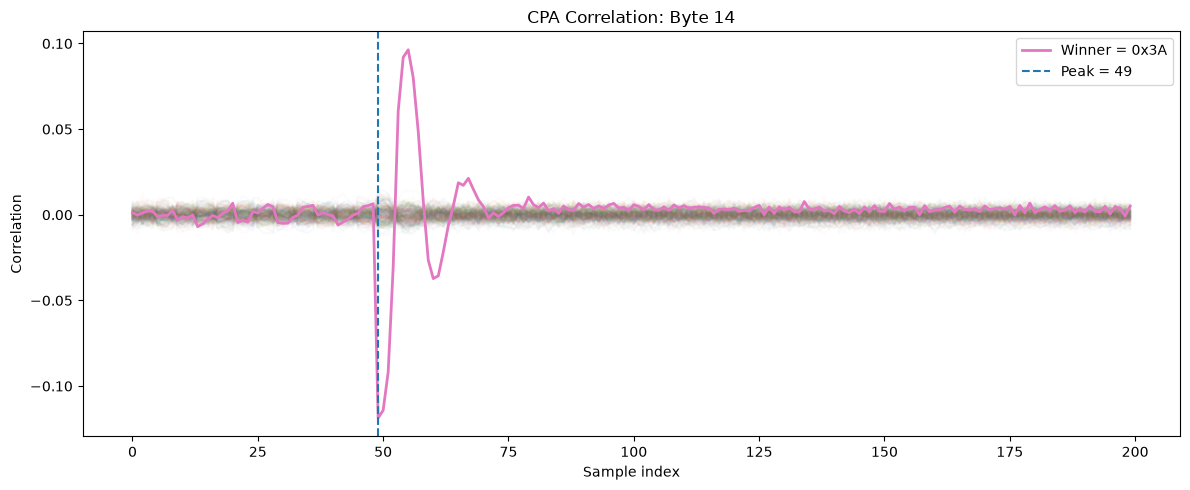

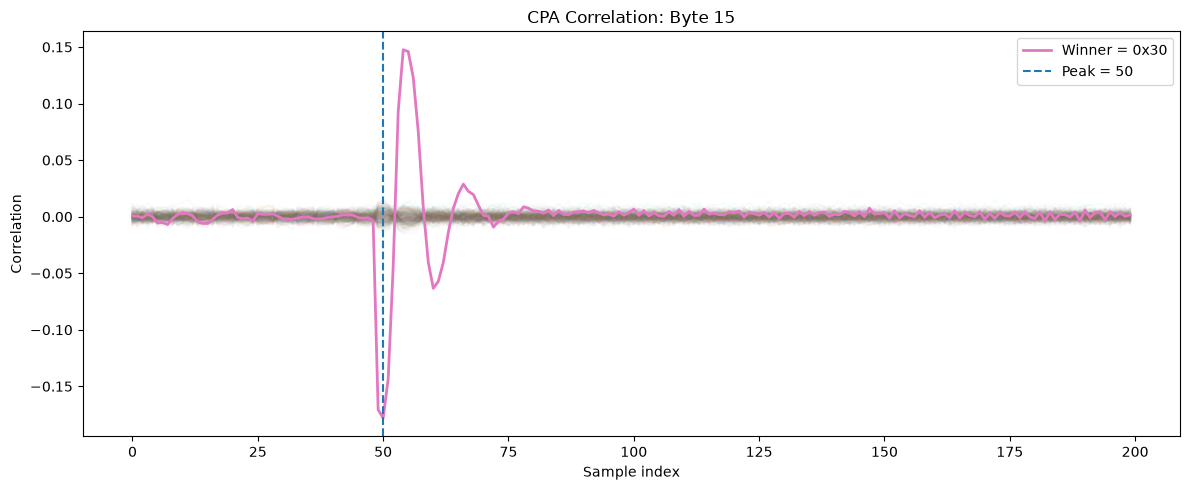

In [25]:
#16 plots
Path(
    "figures/cpa"
).mkdir(
    parents=True,
    exist_ok=True
)

for byte_index in range(16):

    R = correlation_matrices[
        byte_index
    ]

    best_key = results_df.loc[
        byte_index,
        "key"
    ]

    peak_sample = results_df.loc[
        byte_index,
        "peak_sample"
    ]

    plt.figure(figsize=(12, 5))

    for k in range(256):
        plt.plot(
            R[k],
            alpha=0.03
        )

    plt.plot(
        R[best_key],
        linewidth=2,
        label=f"Winner = 0x{best_key:02X}"
    )

    plt.axvline(
        peak_sample,
        linestyle="--",
        label=f"Peak = {peak_sample}"
    )

    plt.xlabel("Sample index")
    plt.ylabel("Correlation")

    plt.title(
        f"CPA Correlation: Byte {byte_index}"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"figures/cpa/"
        f"byte_{byte_index:02d}.png",
        dpi=200
    )

    plt.show()
    plt.close()